# 01 - Dataset Exploration

Exploratory analysis of the RIM-ONE DL dataset, focusing on class distribution, image properties, and visual inspection of retinal fundus images.

## 1. Environment Setup

Import the required libraries and define the paths to the training and test datasets.

In [4]:
from pathlib import Path

import matplotlib.pyplot as plt
from PIL import Image

# Project and dataset paths
PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data/raw/rim_one_dl/partitioned_randomly"

TRAIN_DIR = DATA_DIR / "training_set"
TEST_DIR = DATA_DIR / "test_set"

CLASSES = ["normal", "glaucoma"]

print("Dataset found:", DATA_DIR.is_dir())

Dataset found: True


## 2. Class Distribution

Analyze the number of images in each class and dataset split to identify potential class imbalance.

In [5]:
# Count images in each dataset split
for split_name, split_dir in [
    ("Training", TRAIN_DIR),
    ("Test", TEST_DIR)
]:
    print(f"\n{split_name} set:")

    for class_name in CLASSES:
        class_dir = split_dir / class_name

        images = [
            path for path in class_dir.iterdir()
            if path.suffix.lower() in {".jpg", ".jpeg", ".png", ".tif", ".tiff"}
        ]

        print(f"  {class_name}: {len(images)} images")


Training set:
  normal: 219 images
  glaucoma: 120 images

Test set:
  normal: 94 images
  glaucoma: 52 images


## 3. Image Visualization

Visualize sample fundus images from both classes and inspect their dimensions and color representations.

normal:
  Dimensions: (462, 462)
  Color mode: RGB
glaucoma:
  Dimensions: (547, 547)
  Color mode: RGB


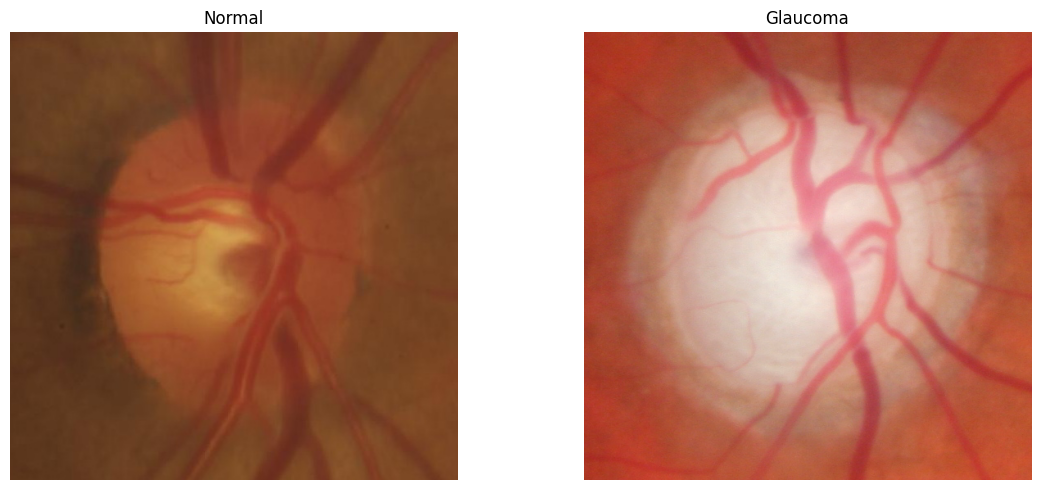

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, class_name in zip(axes, CLASSES):
    class_dir = TRAIN_DIR / class_name

    image_path = next(
        path for path in sorted(class_dir.iterdir())
        if path.suffix.lower() in {".jpg", ".jpeg", ".png", ".tif", ".tiff"}
    )

    with Image.open(image_path) as image:
        print(f"{class_name}:")
        print(f"  Dimensions: {image.size}")
        print(f"  Color mode: {image.mode}")

        ax.imshow(image.convert("RGB"))

    ax.set_title(class_name.capitalize())
    ax.axis("off")

plt.tight_layout()
plt.show()